# Climate Comfort Index (CCI) — 03 Feature Engineering & Horizon Alignment

**Student Name:** Aryan Goel | **Student ID:** 26040826

---

## 1. Leakage-Safe Feature Strategy
To predict the **Next 3 Days (+1, +2, +3 days)** without temporal leakage:
1. **Target Shifting**:
   - $y_{t+1} = \text{CCI}_{t+1}$
   - $y_{t+2} = \text{CCI}_{t+2}$
   - $y_{t+3} = \text{CCI}_{t+3}$
2. **Features**:
   - Autoregressive lags ($t-1, t-2, t-3, t-7, t-14$)
   - Backward-looking rolling statistics (3, 7, 14 days)
   - Cyclical calendar encodings (sine and cosine of day of year and month)
   - Meteorological domain indicators


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.features import build_full_feature_dataset
from src.preprocessing import load_interim_data

daily_df = load_interim_data()
feat_df = build_full_feature_dataset(daily_df)
print(f"Engineered feature matrix: {feat_df.shape[0]} rows, {feat_df.shape[1]} features & targets")


Engineered feature matrix: 2922 rows, 120 features & targets


## 2. Target Correlation Analysis

In [2]:
target_cols = ["target_cci_h1", "target_cci_h2", "target_cci_h3"]
corr_matrix = feat_df.corr(numeric_only=True)

# Top correlated features for 1-day ahead CCI
top_corr_h1 = corr_matrix["target_cci_h1"].drop(target_cols + ["target_whc_h7"]).abs().sort_values(ascending=False).head(15)
print("Top 15 features correlated with +1 Day CCI:")
print(top_corr_h1)


Top 15 features correlated with +1 Day CCI:
cci                           0.605688
cci_roll_mean_3               0.518645
cci_roll_max_3                0.494322
cci_roll_min_3                0.478932
cci_roll_mean_7               0.456061
cci_roll_mean_14              0.430553
cci_roll_max_7                0.409203
cci_lag_1                     0.389060
cci_roll_min_7                0.388048
cci_roll_max_14               0.374944
relative_humidity_2m          0.370902
temp_diff_comfort             0.364476
temperature_2m_roll_max_14    0.361919
temperature_2m_roll_max_3     0.358437
temperature_2m_roll_max_7     0.356511
Name: target_cci_h1, dtype: float64


## 3. Correlation Heatmap of Top Predictors

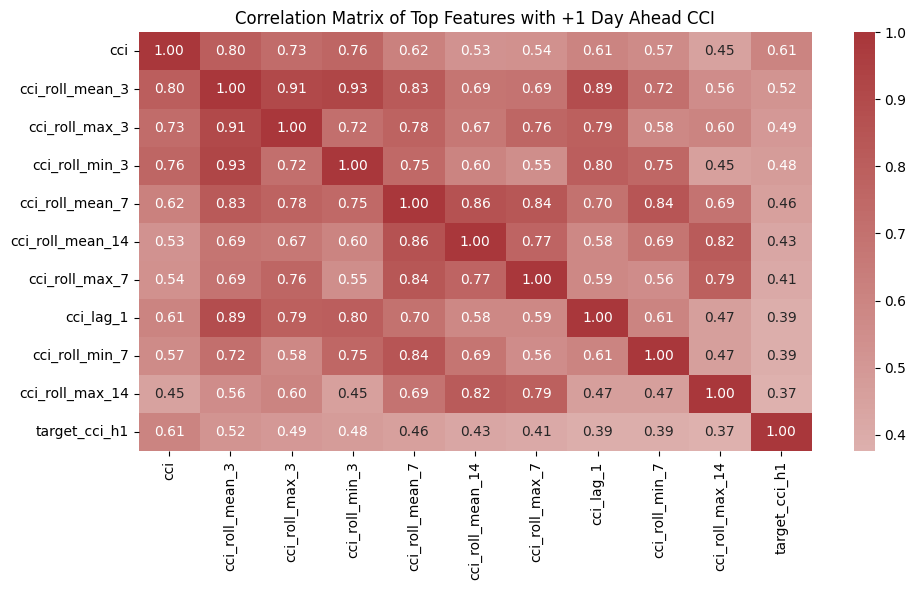

In [3]:
plt.figure(figsize=(10, 6))
top_feats = top_corr_h1.index.tolist()[:10]
sns.heatmap(feat_df[top_feats + ["target_cci_h1"]].corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlation Matrix of Top Features with +1 Day Ahead CCI")
plt.tight_layout()
plt.savefig("reports/figures/cci_feature_correlations.png", dpi=150)
plt.show()


## 4. Verification of Leakage Safety
We verify that lag features and rolling statistics strictly draw on historical information:
- Lag 1 value at index $i$ corresponds precisely to observation $i-1$.
- Forward shifted targets at index $i$ strictly capture future days $i+1, i+2, i+3$.


In [4]:
sample_idx = 50
print(f"Date: {feat_df.loc[sample_idx, 'date']}")
print(f"Today CCI: {feat_df.loc[sample_idx, 'cci']:.2f}")
print(f"Target H1 (t+1): {feat_df.loc[sample_idx, 'target_cci_h1']:.2f} | Actual t+1: {feat_df.loc[sample_idx+1, 'cci']:.2f}")
print(f"Target H2 (t+2): {feat_df.loc[sample_idx, 'target_cci_h2']:.2f} | Actual t+2: {feat_df.loc[sample_idx+2, 'cci']:.2f}")
print(f"Target H3 (t+3): {feat_df.loc[sample_idx, 'target_cci_h3']:.2f} | Actual t+3: {feat_df.loc[sample_idx+3, 'cci']:.2f}")
assert feat_df.loc[sample_idx, 'target_cci_h1'] == feat_df.loc[sample_idx+1, 'cci']
assert feat_df.loc[sample_idx, 'target_cci_h2'] == feat_df.loc[sample_idx+2, 'cci']
assert feat_df.loc[sample_idx, 'target_cci_h3'] == feat_df.loc[sample_idx+3, 'cci']
print("Leakage assertion passed: Zero temporal leakage verified.")


Date: 2018-02-20 00:00:00
Today CCI: 67.15
Target H1 (t+1): 78.75 | Actual t+1: 78.75
Target H2 (t+2): 76.63 | Actual t+2: 76.63
Target H3 (t+3): 76.10 | Actual t+3: 76.10
Leakage assertion passed: Zero temporal leakage verified.
